# CR and ECR gate simulation - QuTiP only

Goal: simulate the cross-resonance (CR) gate and the echoed CR (ECR) sequence for two fixed-frequency transmons,
and find the **qubit frequencies, anharmonicities and coupling** to mimic in the layout.

- No scqubits. Qubits, coupling and pulses are all built with QuTiP operators.
- Units: **GHz and ns**. Hamiltonians are multiplied by 2π so QuTiP sees rad/ns.
- Qubit 1 = **control**, qubit 2 = **target**. Detuning `Δ = f_ctrl - f_tgt`.
- Coupling `J` is the amplitude of `J (a1†a2 + h.c.)`. Resonant avoided crossing = 2J. (Not `g = 4J`.)

Flow (same as before): analytic pre-screen → exact diagonalisation → time-domain simulation.

1. Qubit definitions (`f01, α` ↔ `EJ, EC`) and layout numbers
2. Static two-qubit Hamiltonian: dressed levels, static ZZ, collisions
3. CR theory: ZX / IX rates, analytic vs numerical
4. CR pulse simulation (rotating frame), then a no-RWA lab-frame check
5. Design-space scan for the best `Δ, J`
6. **ECR gate**: pulse sequence, calibration, fidelity, decoherence
7. Layout targets (CSV)

In [1]:
# !pip install qutip -q      # uncomment on Colab if QuTiP is missing
import numpy as np, time, warnings
import matplotlib.pyplot as plt
import qutip as qt
from scipy.optimize import fsolve, minimize, linear_sum_assignment
from scipy.linalg import logm
import scipy.constants as const
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 10})
TWO_PI = 2*np.pi
print('QuTiP', qt.__version__)

QuTiP 5.3.0


## 0. Library (run once)
All helper functions. Read the docstrings if you want to change something; nothing here needs editing for normal use.

In [2]:
# --- transmon: exact cosine model in QuTiP (charge basis) + solver for EJ, EC ---
# ---------------- exact transmon in QuTiP (charge basis) ----------------
def transmon_levels(EJ, EC, ng=0.0, ncut=25, nlev=4):
    N = 2*ncut+1
    n = qt.Qobj(np.diag(np.arange(-ncut, ncut+1)).astype(float))
    cosphi = qt.Qobj(0.5*(np.eye(N, k=1) + np.eye(N, k=-1)))
    H = 4*EC*(n-ng)**2 - EJ*cosphi
    E = H.eigenenergies()[:nlev]
    return E - E[0]

def transmon_f_alpha(EJ, EC, ng=0.0, ncut=25):
    E = transmon_levels(EJ, EC, ng, ncut, 3)
    return E[1], E[2]-2*E[1]

def solve_EJ_EC(f01, alpha, ncut=25):
    EC0 = abs(alpha); EJ0 = (f01+EC0)**2/(8*EC0)
    res = lambda x: [transmon_f_alpha(*x, ncut=ncut)[0]-f01, transmon_f_alpha(*x, ncut=ncut)[1]-alpha]
    return fsolve(res, [EJ0, EC0], xtol=1e-12)

In [3]:
# --- two-qubit Duffing system, dressed states, CR rates from perturbation theory ---
# ---------------- two-qubit Duffing system ----------------
class TwoQubit:
    """ctrl = qubit 1 (first tensor factor), tgt = qubit 2. Frequencies in GHz."""
    def __init__(self, f1, a1, f2, a2, J, nlev=3):
        self.f1, self.a1, self.f2, self.a2, self.J, self.nlev = f1, a1, f2, a2, J, nlev
        d = nlev
        self.b1 = qt.tensor(qt.destroy(d), qt.qeye(d)); self.b2 = qt.tensor(qt.qeye(d), qt.destroy(d))
        self.n1 = self.b1.dag()*self.b1; self.n2 = self.b2.dag()*self.b2
        self.I = qt.tensor(qt.qeye(d), qt.qeye(d))
        self.comp = [(0,0),(0,1),(1,0),(1,1)]
        self.comp_idx = [i*d+j for i,j in self.comp]
    @property
    def Delta(self): return self.f1 - self.f2
    def H_lab(self, coupling='exchange'):
        """Lab-frame static H in rad/ns."""
        b1,b2 = self.b1,self.b2
        H = self.f1*self.n1 + self.a1/2*b1.dag()*b1.dag()*b1*b1 + self.f2*self.n2 + self.a2/2*b2.dag()*b2.dag()*b2*b2
        if coupling == 'exchange':   # RWA exchange  J(a1^dag a2 + h.c.)
            H = H + self.J*(b1.dag()*b2 + b1*b2.dag())
        else:                         # full capacitive charge-charge, n_j = i(a^dag - a)
            q1 = 1j*(b1.dag()-b1); q2 = 1j*(b2.dag()-b2)
            H = H + self.J*q1*q2
        return TWO_PI*H
    def H_rot(self, wd, Omega=0.0, coupling='exchange'):
        """Time-independent frame rotating at wd (GHz) for BOTH qubits, RWA, constant control drive Omega (GHz Rabi rate on ctrl)."""
        b1,b2 = self.b1,self.b2
        H = (self.f1-wd)*self.n1 + self.a1/2*b1.dag()*b1.dag()*b1*b1 + (self.f2-wd)*self.n2 + self.a2/2*b2.dag()*b2.dag()*b2*b2
        H = H + self.J*(b1.dag()*b2 + b1*b2.dag()) + 0.5*Omega*(b1 + b1.dag())
        return TWO_PI*H

def label_eigs(H, d):
    """Return energies/eigvecs sorted by label (i,j) using max-overlap (Hungarian) assignment with bare product states."""
    E, V = H.eigenstates()
    M = np.column_stack([v.full().ravel() for v in V])      # (d*d, d*d): rows bare, cols eig
    r, c = linear_sum_assignment(-np.abs(M)**2)
    lab = {}
    for bare_idx, eig_idx in zip(r, c):
        v = M[:, eig_idx]
        v = v*np.exp(-1j*np.angle(v[bare_idx]))          # gauge: component on its own bare state is real & positive
        lab[(bare_idx//d, bare_idx % d)] = (E[eig_idx], v)
    return lab

def dressed_info(sys_):
    d = sys_.nlev
    lab = label_eigs(sys_.H_lab(), d)
    E = {k: v[0]/TWO_PI for k, v in lab.items()}   # GHz
    out = dict(E=E, vec=lab)
    out['f1_d'] = E[(1,0)]-E[(0,0)]; out['f2_d'] = E[(0,1)]-E[(0,0)]
    out['zz_MHz'] = (E[(1,1)]-E[(1,0)]-E[(0,1)]+E[(0,0)])*1e3
    return out

# ---------------- Pauli algebra & effective Hamiltonian ----------------
PAULI = {'I': np.eye(2), 'X': np.array([[0,1],[1,0]]), 'Y': np.array([[0,-1j],[1j,0]]), 'Z': np.diag([1.,-1.])}
def pauli_decomp(H4):
    out = {}
    for p in 'IXYZ':
        for q in 'IXYZ':
            out[p+q] = np.real(np.trace(np.kron(PAULI[p], PAULI[q]) @ H4))/4
    return out


def cr_rates(sys_, Omega, wd=None):
    """CR Pauli rates (in MHz, H = sum c_P P, c_P/2pi) for a control drive H_d=(Omega/2)(a1+a1^dag) [Omega in GHz]
    resonant with the dressed target frequency.
      IX, ZX : first order in Omega, exact in J (matrix elements between dressed states)
      zeta_static : static ZZ (energy shift of |11>), Stark_* : second-order drive-induced shifts (virtual control/leakage transitions)."""
    d = sys_.nlev
    lab = label_eigs(sys_.H_lab(), d)
    if wd is None: wd = (lab[(0,1)][0]-lab[(0,0)][0])/TWO_PI
    keys = sorted(lab.keys())
    V = np.column_stack([lab[k][1] for k in keys])                  # dressed vectors (columns)
    e = np.array([lab[k][0]/TWO_PI - wd*(k[0]+k[1]) for k in keys])  # energies in the drive frame (GHz)
    D = V.conj().T @ (sys_.b1 + sys_.b1.dag()).full() @ V             # drive operator in dressed basis
    ix = {k: i for i, k in enumerate(keys)}
    x = {c: 0.5*Omega*D[ix[(c,1)], ix[(c,0)]].real for c in (0,1)}   # target-X coefficient per control state (GHz)
    out = {'IX': (x[0]+x[1])/2*1e3, 'ZX': (x[0]-x[1])/2*1e3}
    shift = {}
    for k in sys_.comp:
        s = 0.0
        partner = (k[0], 1-k[1])
        for m in keys:
            if m == k or m == partner: continue
            s += abs(0.5*Omega*D[ix[m], ix[k]])**2/(e[ix[k]]-e[ix[m]])
        shift[k] = s
    E = {k: e[ix[k]] for k in sys_.comp}
    out['zeta_static'] = (E[(1,1)]-E[(1,0)]-E[(0,1)]+E[(0,0)])*1e3
    out['Stark_zeta']  = (shift[(1,1)]-shift[(1,0)]-shift[(0,1)]+shift[(0,0)])*1e3
    out['Stark_IZ']    = (shift[(0,0)]-shift[(0,1)]+shift[(1,0)]-shift[(1,1)])/4*1e3
    out['Stark_ZI']    = (shift[(0,0)]+shift[(0,1)]-shift[(1,0)]-shift[(1,1)])/4*1e3
    return out

In [4]:
# --- pulse shapes and the qubit-frame (RWA) time-dependent Hamiltonian ---
# ======================= pulse-level simulation =======================
def lifted_gauss_square(t, t0, t_flat, t_edge, sigma=None):
    """Unit-height flat-top with lifted-Gaussian rise/fall. Total duration = t_flat + 2*t_edge, starts at t0."""
    if sigma is None: sigma = t_edge/2.5
    g = lambda x: np.exp(-0.5*(x/sigma)**2)
    g0 = g(t_edge)
    x = t - t0
    y = np.zeros_like(t)
    r = (x >= 0) & (x < t_edge);                       y[r] = (g(x[r]-t_edge)-g0)/(1-g0)
    f = (x >= t_edge) & (x < t_edge+t_flat);           y[f] = 1.0
    d = (x >= t_edge+t_flat) & (x <= 2*t_edge+t_flat); y[d] = (g(x[d]-t_edge-t_flat)-g0)/(1-g0)
    return y

def gauss_pulse(t, t0, dur, sigma=None):
    """Unit-height lifted Gaussian of total length dur starting at t0."""
    if sigma is None: sigma = dur/4
    x = t - t0; y = np.zeros_like(t); m = (x >= 0) & (x <= dur)
    g = lambda u: np.exp(-0.5*(u/sigma)**2); g0 = g(dur/2)
    y[m] = (g(x[m]-dur/2)-g0)/(1-g0)
    return y

def pi_pulse_amp(dur, sigma=None):
    """Peak Rabi frequency (GHz) of a lifted-Gaussian pulse of length dur giving a pi rotation (area of Omega(t) dt = pi rad)."""
    tt = np.linspace(0, dur, 4001); env = gauss_pulse(tt, 0, dur, sigma)
    return 0.5/np.trapezoid(env, tt)      # 2*pi*A*area = pi  ->  A = 1/(2*area)

def build_H_evo(sys_, tlist, drives):
    """Qubit-frame (rotating at bare f1,f2) RWA Hamiltonian as QobjEvo, rad/ns.
       drives: list of (qubit(1|2), f_drive[GHz], E(t) complex array [GHz Rabi rate, on tlist])
       drive term: (1/2)(E^* a e^{+i 2pi (fd-fq) t} + h.c.)"""
    b1, b2 = sys_.b1, sys_.b2
    H0 = TWO_PI*(sys_.a1/2*b1.dag()*b1.dag()*b1*b1 + sys_.a2/2*b2.dag()*b2.dag()*b2*b2)
    ph = TWO_PI*(sys_.f1-sys_.f2)*tlist
    Jc = TWO_PI*sys_.J
    terms = [H0,
             [b1.dag()*b2, Jc*np.exp(1j*ph)], [b1*b2.dag(), Jc*np.exp(-1j*ph)]]
    for q, fd, E in drives:
        a = b1 if q == 1 else b2
        fq = sys_.f1 if q == 1 else sys_.f2
        w = np.exp(1j*TWO_PI*(fd-fq)*tlist)
        terms.append([a,       0.5*TWO_PI*np.conj(E)*w])
        terms.append([a.dag(), 0.5*TWO_PI*E*np.conj(w)])
    return qt.QobjEvo(terms, tlist=tlist)

def make_tlist(T, sys_, dt_max=0.05):
    fmax = max(abs(sys_.f1-sys_.f2), 0.2) + 0.1
    dt = min(dt_max, 1/(40*fmax))
    return np.linspace(0, T, int(np.ceil(T/dt))+1)

def propagate_U(sys_, tlist, drives, nsteps=None):
    """Full (nlev^2 x nlev^2) propagator in the qubit frame via QuTiP."""
    H = build_H_evo(sys_, tlist, drives)
    U = qt.propagator(H, tlist[-1], options={'atol': 1e-11, 'rtol': 1e-9, 'nsteps': 100000, 'method': 'vern9'})
    return U

In [5]:
# --- gate analysis, ECR sequence, calibration, checks, decoherence ---
# ======================= gate analysis =======================
def Rz(phi): return np.diag([np.exp(-0.5j*phi), np.exp(0.5j*phi)])
def ZXrot(theta):
    ZX = np.kron(PAULI['Z'], PAULI['X']); return np.cos(theta/2)*np.eye(4) - 1j*np.sin(theta/2)*ZX
XC = np.kron(PAULI['X'], np.eye(2))          # X on control

def comp_block(sys_, U, T):
    """4x4 computational-subspace block (dressed basis, dressed single-qubit frame) of a qubit-frame propagator U(T)."""
    d = sys_.nlev
    lab = label_eigs(sys_.H_lab(), d)
    V = np.column_stack([lab[k][1] for k in sys_.comp])                       # lab-frame dressed comp states
    F = TWO_PI*(sys_.f1*sys_.n1 + sys_.f2*sys_.n2).full().diagonal()          # bare frame generator
    Ulab = np.diag(np.exp(-1j*F*T)) @ U.full()                                # undo qubit frame -> lab frame
    W = V.conj().T @ Ulab @ V
    E = {k: lab[k][0] for k in lab}
    w_frame = np.array([0, E[(0,1)]-E[(0,0)], E[(1,0)]-E[(0,0)], E[(1,0)]+E[(0,1)]-2*E[(0,0)]])  # dressed single-qubit energies (rad/ns)
    return np.diag(np.exp(1j*w_frame*T)) @ W

def avg_fidelity(M):
    """Average gate fidelity (Pedersen 2007) of a possibly non-unitary 4x4 block M = U_ideal^dag U_sim (leakage reduces it)."""
    d = M.shape[0]
    return (np.real(np.trace(M.conj().T@M)) + abs(np.trace(M))**2)/(d*(d+1))

def fidelity_with_virtual_z(Ub, Uideal, n_starts=3, seed=0, z0=None):
    """Maximise avg fidelity over free single-qubit Z rotations before and after the gate (virtual-Z / frame updates)."""
    rng = np.random.default_rng(seed)
    def Zl(p): return np.kron(Rz(p[0]), Rz(p[1]))
    def cost(p): return 1-avg_fidelity(Uideal.conj().T @ Zl(p[:2]) @ Ub @ Zl(p[2:]))
    starts = ([np.asarray(z0)] if z0 is not None else []) + [np.zeros(4)] + [rng.uniform(-np.pi, np.pi, 4) for _ in range(max(n_starts-1-(z0 is not None), 0))]
    best = None
    for x0 in starts[:max(n_starts, 1)]:
        r = minimize(cost, x0, method='BFGS', options={'gtol': 1e-9})
        if best is None or r.fun < best.fun: best = r
    return 1-best.fun, best.x

def leakage(Ub): return 1-np.real(np.trace(Ub.conj().T@Ub))/4

# ======================= pulse sequences =======================
def cr_sequence(sys_, A, t_flat, t_edge, phase=0.0, t0=0.0, A_t=0.0):
    """Single CR pulse (control drive at the dressed target frequency). Optional cancellation tone A_t (GHz) on the TARGET
    at the same frequency/envelope. Returns tlist, drives, T."""
    T = t_flat + 2*t_edge
    tl = make_tlist(T, sys_)
    f2d = dressed_info(sys_)['f2_d']
    env = lifted_gauss_square(tl, 0, t_flat, t_edge)*np.exp(1j*phase)
    drives = [(1, f2d, (A*env).astype(complex))]
    if A_t != 0.0: drives.append((2, f2d, (A_t*env).astype(complex)))
    return tl, drives, T

def ecr_sequence(sys_, A, t_flat, t_edge, t_x=20.0, gap=2.0, phase=0.0, final_x=False, x_amp_scale=1.0, A2=None):
    """ECR: CR(+A) - pi_x(control) - CR(-A).  Optional final pi_x on control to restore the control state."""
    if A2 is None: A2 = -A
    t_cr = t_flat + 2*t_edge
    T = 2*t_cr + t_x + 2*gap + (t_x + gap if final_x else 0.0)
    tl = make_tlist(T, sys_)
    di = dressed_info(sys_)
    cr = lifted_gauss_square(tl, 0, t_flat, t_edge)
    cr2 = lifted_gauss_square(tl, t_cr + gap + t_x + gap, t_flat, t_edge)
    E_cr = (A*cr + A2*cr2)*np.exp(1j*phase)
    xa = pi_pulse_amp(t_x)*x_amp_scale
    E_x = xa*gauss_pulse(tl, t_cr + gap, t_x)
    if final_x: E_x = E_x + xa*gauss_pulse(tl, 2*t_cr + 2*gap + t_x + gap, t_x)
    drives = [(1, di['f2_d'], E_cr.astype(complex)), (1, di['f1_d'], E_x.astype(complex))]
    return tl, drives, T

def ecr_ideal(final_x=False):
    U = ZXrot(-np.pi/4*1.0) @ XC @ ZXrot(np.pi/4)           # CR(+pi/4) -> X_c -> CR(-pi/4); later pulses act from the left
    # note: ZXrot(theta) = exp(-i theta/2 ZX); half-angle pi/4 per CR gives net ZX(pi/2)
    return U

# ======================= calibration helpers =======================
def edge_area(t_edge):
    tt = np.linspace(0, 2*t_edge, 2001); return np.trapezoid(lifted_gauss_square(tt, 0, 0, t_edge), tt)

def guess_cr(sys_, Omega, t_edge, theta=np.pi/4):
    """Analytic first guess: flat-top length so that the CR rotation angle equals theta (ZX half-angle; theta=pi/4 -> half of an ECR)."""
    r = cr_rates(sys_, abs(Omega)); c = TWO_PI*abs(r['ZX'])*1e-3
    A = abs(Omega)*(1.0 if r['ZX'] > 0 else -1.0)           # sign chosen so that the ZX rotation is positive
    return A, max(theta/(2*c) - edge_area(t_edge), 0.0)

def ecr_eval(sys_, x, t_edge=10.0, t_x=20.0, gap=2.0, final_x=False, z0=None, n_starts=2):
    """x = (A, t_flat[, phase]) ; returns (F, leakage, T, z)."""
    A, tf = x[0], max(x[1], 0.0); ph = x[2] if len(x) > 2 else 0.0
    tl, dr, T = ecr_sequence(sys_, A, tf, t_edge, t_x=t_x, gap=gap, phase=ph, final_x=final_x)
    Ub = comp_block(sys_, propagate_U(sys_, tl, dr), T)
    F, z = fidelity_with_virtual_z(Ub, ecr_ideal(), n_starts=n_starts, z0=z0)
    return F, leakage(Ub), T, z

def calibrate_ecr(sys_, Omega, t_edge=10.0, t_x=20.0, gap=2.0, maxiter=80, fit_phase=True, verbose=False):
    """Nelder-Mead over (CR amplitude, flat-top length, CR phase) maximising the ECR average gate fidelity (with virtual Z).
    Omega = starting guess for the CR Rabi rate in GHz."""
    A0, tf0 = guess_cr(sys_, Omega, t_edge)
    tf0 = float(np.clip(tf0, 5.0, 400.0))
    state = {'z': None}
    def cost(x):
        F, leak, T, z = ecr_eval(sys_, x, t_edge, t_x, gap, z0=state['z'], n_starts=2)
        state['z'] = z
        return 1-F
    x0 = [A0, tf0, 0.0] if fit_phase else [A0, tf0]
    sim = [x0] + [list(np.array(x0) + np.eye(len(x0))[k]*dx) for k, dx in enumerate([0.1*A0, 0.1*tf0+2, 0.1][:len(x0)])]
    res = minimize(cost, x0, method='Nelder-Mead', options={'xatol': 1e-4, 'fatol': 1e-7, 'maxiter': maxiter, 'initial_simplex': sim})
    F, leak, T, z = ecr_eval(sys_, res.x, t_edge, t_x, gap, n_starts=5)
    return dict(A=res.x[0], t_flat=max(res.x[1], 0.0), phase=(res.x[2] if fit_phase else 0.0), F=F, leak=leak, T=T, z=z, nfev=res.nfev, A0=A0, t0=tf0)

# ======================= design helpers, checks, decoherence =======================
def collision_report(f1, a1, f2, a2):
    """Distance (MHz) of the design from the frequency collisions that matter for a CR/ECR gate (ctrl=1, tgt=2)."""
    D = f1-f2
    pts = {'ctrl = target  (D = 0)': 0.0,
           'tgt 1-2 = ctrl 0-1  (D = a_tgt)': a2,
           'ctrl 1-2 = tgt 0-1  (D = -a_ctrl)': -a1,
           'two-photon ctrl 0-2  (D = -a_ctrl/2)': -a1/2}
    return {k: abs(D-v)*1e3 for k, v in pts.items()}

def zeta_analytic(J, a1, a2, D):
    """Static ZZ (GHz) of two coupled transmons, 2nd order in J: 2 J^2 (a1+a2) / ((D+a1)(D-a2))."""
    return 2*J**2*(a1+a2)/((D+a1)*(D-a2))

def exact_zeta(f1, a1, f2, a2, J, ncut=25, nlev=3):
    """Static ZZ (MHz) using the *exact* cosine transmons (charge basis, built in QuTiP), truncated to nlev levels each,
    capacitive charge-charge coupling g*n1*n2 with g set so that the 0-1 exchange rate equals J."""
    def one(EJ, EC):
        N = 2*ncut+1
        n = qt.Qobj(np.diag(np.arange(-ncut, ncut+1)*1.0))
        cosphi = qt.Qobj(0.5*(np.eye(N, k=1)+np.eye(N, k=-1)))
        E, V = (4*EC*n*n - EJ*cosphi).eigenstates()
        Vm = np.column_stack([V[i].full().ravel() for i in range(nlev)])
        return E[:nlev]-E[0], Vm.conj().T @ n.full() @ Vm
    E1, n1 = one(*solve_EJ_EC(f1, a1, ncut)); E2, n2 = one(*solve_EJ_EC(f2, a2, ncut))
    g = J/(abs(n1[0, 1])*abs(n2[0, 1]))
    H = qt.Qobj(np.kron(np.diag(E1), np.eye(nlev)) + np.kron(np.eye(nlev), np.diag(E2)) + g*np.kron(n1, n2), dims=[[nlev, nlev], [nlev, nlev]])
    lab = label_eigs(H, nlev)
    return (lab[(1,1)][0]-lab[(1,0)][0]-lab[(0,1)][0]+lab[(0,0)][0])*1e3

def collapse_ops(sys_, T1_us=100.0, T2_us=100.0):
    """Lindblad collapse operators (T1 + pure dephasing) for both qubits, rates in 1/ns. Zero temperature."""
    c = []
    for a in (sys_.b1, sys_.b2):
        g1 = 1/(T1_us*1e3); gphi = max(1/(T2_us*1e3) - 1/(2*T1_us*1e3), 0.0)
        c += [np.sqrt(g1)*a, np.sqrt(2*gphi)*a.dag()*a]
    return c

def lab_frame_cr(sys_, A, t_flat, t_edge, ctrl, dt=0.01, A_t=0.0):
    """Full lab-frame sim: NO rotating frame, NO RWA, capacitive charge-charge coupling, cosine carrier on the control charge operator.
    Returns time array and target P(1) for control prepared in |ctrl>."""
    T = t_flat+2*t_edge; tl = np.arange(0, T+dt, dt)
    f2d = dressed_info(sys_)['f2_d']
    env = A*lifted_gauss_square(tl, 0, t_flat, t_edge)
    q1 = 1j*(sys_.b1.dag()-sys_.b1)                                   # control charge operator
    H = [sys_.H_lab('charge'), [TWO_PI*q1, env*np.cos(TWO_PI*f2d*tl)]]
    if A_t != 0.0:                                                     # cancellation tone on the target charge operator
        q2 = 1j*(sys_.b2.dag()-sys_.b2)
        H.append([TWO_PI*q2, (A_t/A)*env*np.cos(TWO_PI*f2d*tl)])
    lab = label_eigs(sys_.H_lab('charge'), sys_.nlev)
    psi0 = qt.Qobj(lab[(ctrl, 0)][1].reshape(-1, 1), dims=[[sys_.nlev]*2, [1]*2])
    d = sys_.nlev
    P1 = qt.tensor(qt.qeye(d), qt.fock_dm(d, 1))
    res = qt.sesolve(H, psi0, tl, e_ops=[P1], options={'atol': 1e-9, 'rtol': 1e-7, 'nsteps': 10**6, 'method': 'vern9'})
    return tl, np.real(res.expect[0])

def cr_bloch(sys_, A, t_flat, t_edge, ctrl, A_t=0.0):
    """Qubit-frame (RWA) CR pulse: target Bloch vector (in the frame rotating at the drive) and populations for control prepared in |ctrl>."""
    tl, dr, T = cr_sequence(sys_, A, t_flat, t_edge, A_t=A_t)
    H = build_H_evo(sys_, tl, dr)
    d = sys_.nlev; lab = label_eigs(sys_.H_lab(), d)
    psi0 = qt.Qobj(lab[(ctrl, 0)][1].reshape(-1, 1), dims=[[d, d], [1, 1]])
    ket = lambda i: qt.basis(d, i)
    sm = qt.tensor(qt.qeye(d), ket(0)*ket(1).dag())                     # target |0><1|
    P = lambda s, i: qt.tensor(s, ket(i)*ket(i).dag())
    ops_ = [sm, P(qt.qeye(d), 0), P(qt.qeye(d), 1), P(qt.qeye(d), 2), qt.tensor(ket(2)*ket(2).dag(), qt.qeye(d)), qt.tensor(ket(1)*ket(1).dag(), qt.qeye(d))]
    res = qt.sesolve(H, psi0, tl, e_ops=ops_, options={'atol': 1e-10, 'rtol': 1e-8, 'nsteps': 10**6, 'method': 'vern9'})
    f2d = dressed_info(sys_)['f2_d']
    rot = np.exp(1j*TWO_PI*(f2d-sys_.f2)*tl)                           # to frame rotating at the drive frequency
    s_m = res.expect[0]*rot
    X = 2*np.real(s_m); Y = -2*np.imag(s_m)                             # <sigma_x>, <sigma_y> from <|0><1|>
    Z = np.real(res.expect[1]-res.expect[2])
    return dict(t=tl, X=X, Y=Y, Z=Z, P_t1=np.real(res.expect[2]), P_t2=np.real(res.expect[3]), P_c2=np.real(res.expect[4]), P_c1=np.real(res.expect[5]))


def calibrate_cancel_tone(sys_, A, t_flat, t_edge):
    """Amplitude A_t (GHz) of a target tone that nulls the target rotation for control=|0> (cancels IX + ZX for that branch).
    Result: target only rotates when the control is |1>  (CNOT-like conditional flip)."""
    r = cr_rates(sys_, abs(A)); x0 = (r['IX']+r['ZX'])*1e-3*np.sign(A)       # GHz, target-X coefficient for ctrl=0
    cost = lambda At: np.mean(cr_bloch(sys_, A, t_flat, t_edge, 0, A_t=At)['P_t1'])
    cands = [-2*x0, 2*x0]; g = min(cands, key=cost)
    res = minimize(lambda v: cost(v[0]), [g], method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-8, 'initial_simplex': [[g], [g*1.1]]})
    return res.x[0]

def tune_flip_length(sys_, A, A_t, t_flat0, t_edge, span=0.3, n=13):
    """Scan flat-top length so that the target is flipped (P1 max) when control=|1>."""
    ts = t_flat0*np.linspace(1-span, 1+span, n)
    p = [cr_bloch(sys_, A, t, t_edge, 1, A_t=A_t)['P_t1'][-1] for t in ts]
    return ts[int(np.argmax(p))], ts, np.array(p)

# ---- CNOT-equivalent frame for the ECR: fit local single-qubit gates so that ECR_ideal -> CNOT ----
def u3(th, ph, lam):
    return np.array([[np.cos(th/2), -np.exp(1j*lam)*np.sin(th/2)], [np.exp(1j*ph)*np.sin(th/2), np.exp(1j*(ph+lam))*np.cos(th/2)]])
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
def local_gates(p): return np.kron(u3(*p[0:3]), u3(*p[3:6])), np.kron(u3(*p[6:9]), u3(*p[9:12]))
def fit_local_cnot(Uideal, n_try=30, seed=1):
    """Find L_pre, L_post (tensor products of single-qubit gates) with L_post * Uideal * L_pre = CNOT."""
    rng = np.random.default_rng(seed); best = None
    def cost(p):
        Lpost, Lpre = local_gates(p); return 1-abs(np.trace(CNOT.conj().T @ Lpost @ Uideal @ Lpre))**2/16
    for _ in range(n_try):
        r = minimize(cost, rng.uniform(-np.pi, np.pi, 12), method='BFGS', options={'gtol': 1e-10})
        if best is None or r.fun < best.fun: best = r
        if best.fun < 1e-10: break
    return best.x, best.fun

## 1. Qubit definitions

Edit the **design knobs** below. Everything downstream follows.

- Control is *below* the target here (`Δ < 0`, `|Δ| < |α|`): the usual CR window, away from all collisions.
- `J` is the exchange rate between the qubits.

In [6]:
# ============ DESIGN KNOBS (GHz) ============
f_ctrl, alpha_ctrl = 4.85, -0.300      # control qubit  f01, anharmonicity
f_tgt,  alpha_tgt  = 5.00, -0.300      # target  qubit  f01, anharmonicity
J    = 0.003                           # exchange coupling (GHz) -> 3 MHz
NLEV = 3                               # levels kept per transmon (|0>,|1>,|2>)
# ============================================

EJc, ECc = solve_EJ_EC(f_ctrl, alpha_ctrl)
EJt, ECt = solve_EJ_EC(f_tgt,  alpha_tgt)
sysd = TwoQubit(f_ctrl, alpha_ctrl, f_tgt, alpha_tgt, J, NLEV)

e_over_h = const.e**2/(2*const.h)*1e-9*1e15      # e^2/2h in GHz*fF  (=19.37)
Phi0 = const.h/(2*const.e)
rows = []
for name, EJ, EC in [('control', EJc, ECc), ('target', EJt, ECt)]:
    Ic_nA = 4*np.pi*const.e*EJ*1e9*1e9            # Ic = 4*pi*e*EJ/h  (EJ in GHz)
    Rn = np.pi*180e-6/(2*Ic_nA*1e-9)              # Ambegaokar-Baratoff, Al gap 180 ueV (approx.)
    rows.append((name, EJ, EC, EJ/EC, e_over_h/EC, Ic_nA, Rn/1e3))
print(f"{'qubit':8s}{'EJ(GHz)':>10s}{'EC(GHz)':>10s}{'EJ/EC':>8s}{'C_sum(fF)':>11s}{'Ic(nA)':>9s}{'Rn(kOhm)':>10s}")
for r in rows: print(f"{r[0]:8s}{r[1]:10.3f}{r[2]:10.4f}{r[3]:8.1f}{r[4]:11.1f}{r[5]:9.1f}{r[6]:10.2f}")
print()
for name, EJ, EC, f, a in [('control', EJc, ECc, f_ctrl, alpha_ctrl), ('target', EJt, ECt, f_tgt, alpha_tgt)]:
    fe, ae = transmon_f_alpha(EJ, EC)
    print(f'{name}: exact cosine model -> f01 = {fe:.5f}, alpha = {ae:.5f} GHz  (target {f}, {a})')

qubit      EJ(GHz)   EC(GHz)   EJ/EC  C_sum(fF)   Ic(nA)  Rn(kOhm)
control     12.617    0.2603    48.5       74.4     25.4     11.13
target      13.310    0.2615    50.9       74.1     26.8     10.55

control: exact cosine model -> f01 = 4.85000, alpha = -0.30000 GHz  (target 4.85, -0.3)
target: exact cosine model -> f01 = 5.00000, alpha = -0.30000 GHz  (target 5.0, -0.3)


In [7]:
# Cooper-pair-box levels from the exact transmon: how anharmonic / charge-sensitive is the design?
for name, EJ, EC in [('control', EJc, ECc), ('target', EJt, ECt)]:
    E = transmon_levels(EJ, EC, ng=0.0, nlev=4)
    E_half = transmon_levels(EJ, EC, ng=0.5, nlev=4)
    print(f'{name}: levels (GHz) = {np.round(E,4)}   charge dispersion of f01 = {abs((E_half[1]-E_half[0])-(E[1]-E[0]))*1e6:.3f} kHz')

control: levels (GHz) = [ 0.      4.85    9.4    13.6145]   charge dispersion of f01 = 13.457 kHz
target: levels (GHz) = [ 0.     5.     9.7   14.065]   charge dispersion of f01 = 8.867 kHz


## 2. Static two-qubit Hamiltonian

`H = Σ f_i n_i + α_i/2 · a†a†aa + J (a1†a2 + a1a2†)`, built from `qt.destroy` and `qt.tensor`.

Dressed states are labelled by maximum overlap with the bare product states (this replaces scqubits' `dressed_index`).

In [8]:
di = dressed_info(sysd)
print(f"Delta = f_ctrl - f_tgt = {sysd.Delta*1e3:+.0f} MHz")
print(f"dressed f_ctrl = {di['f1_d']:.6f} GHz, dressed f_tgt = {di['f2_d']:.6f} GHz")
print(f"static ZZ (zeta)  Duffing model : {di['zz_MHz']:+.4f} MHz")
print(f"                  analytic      : {zeta_analytic(J, alpha_ctrl, alpha_tgt, sysd.Delta)*1e3:+.4f} MHz   [2J^2(a1+a2)/((D+a1)(D-a2))]")
print(f"                  exact cosine  : {exact_zeta(f_ctrl, alpha_ctrl, f_tgt, alpha_tgt, J):+.4f} MHz   (cosine transmons, same J)")
print()
print('Distance to collisions (MHz), want > ~50:')
for k, v in collision_report(f_ctrl, alpha_ctrl, f_tgt, alpha_tgt).items(): print(f'  {k:42s} {v:7.0f}')

Delta = f_ctrl - f_tgt = -150 MHz
dressed f_ctrl = 4.849940 GHz, dressed f_tgt = 5.000060 GHz
static ZZ (zeta)  Duffing model : +0.1599 MHz
                  analytic      : +0.1600 MHz   [2J^2(a1+a2)/((D+a1)(D-a2))]
                  exact cosine  : +0.1502 MHz   (cosine transmons, same J)

Distance to collisions (MHz), want > ~50:
  ctrl = target  (D = 0)                         150
  tgt 1-2 = ctrl 0-1  (D = a_tgt)                150
  ctrl 1-2 = tgt 0-1  (D = -a_ctrl)              450
  two-photon ctrl 0-2  (D = -a_ctrl/2)           300


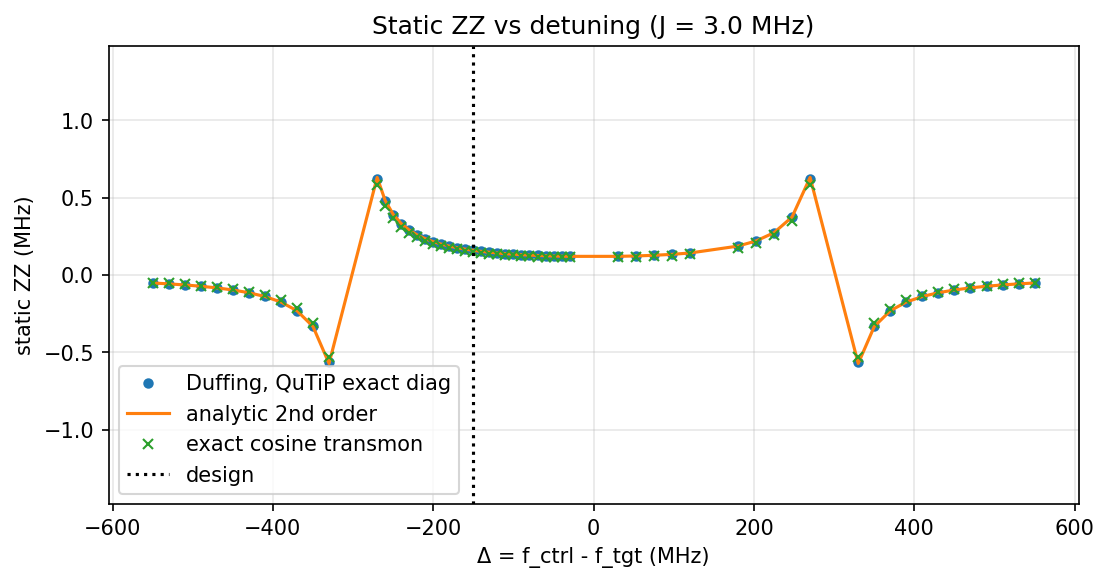

In [9]:
# static ZZ vs detuning: Duffing (QuTiP exact diag) vs analytic vs exact cosine transmons
Ds = np.concatenate([np.linspace(-0.55, -0.33, 12), np.linspace(-0.27, -0.03, 25), np.linspace(0.03, 0.12, 5), np.linspace(0.18, 0.27, 5), np.linspace(0.33, 0.55, 12)])
zd, za, ze = [], [], []
for D in Ds:
    s_ = TwoQubit(f_tgt+D, alpha_ctrl, f_tgt, alpha_tgt, J, NLEV)
    zd.append(dressed_info(s_)['zz_MHz']); za.append(zeta_analytic(J, alpha_ctrl, alpha_tgt, D)*1e3)
    ze.append(exact_zeta(f_tgt+D, alpha_ctrl, f_tgt, alpha_tgt, J))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(Ds*1e3, zd, 'o', ms=4, label='Duffing, QuTiP exact diag')
ax.plot(Ds*1e3, za, '-', label='analytic 2nd order')
ax.plot(Ds*1e3, ze, 'x', ms=5, label='exact cosine transmon')
ax.axvline(sysd.Delta*1e3, color='k', ls=':', label='design')
ax.set_ylim(-3*abs(zeta_analytic(J, alpha_ctrl, alpha_tgt, sysd.Delta)*1e3)-1, 3*abs(zeta_analytic(J, alpha_ctrl, alpha_tgt, sysd.Delta)*1e3)+1)
ax.set_xlabel('Δ = f_ctrl - f_tgt (MHz)'); ax.set_ylabel('static ZZ (MHz)'); ax.set_title(f'Static ZZ vs detuning (J = {J*1e3:.1f} MHz)'); ax.legend()
plt.tight_layout(); plt.show()

## 3. CR theory: what the drive does

Drive on the control at the **target** frequency, `H_d = (Ω/2)(a1 + a1†)`.
To first order in `J` and `Ω` (derived with perturbation theory, checked below):

- `ZX = -(Ω J / 2) · α_c / (Δ (Δ + α_c))`  ← the useful term
- `IX = -(Ω J / 2) / (Δ + α_c)`  ← unwanted, cancelled by the echo in ECR
- Rotation: `exp(-i θ/2 · ZX)` with `θ = 2·c·t`, `c = 2π·ZX` (rad/ns). Half an ECR = `θ = π/4`.

`cr_rates` gets ZX / IX from dressed-state matrix elements (exact in J), and the drive-induced Stark shifts from 2nd-order perturbation theory.

In [10]:
Om_ref = 0.060                                  # drive Rabi rate on control, GHz (60 MHz)
r = cr_rates(sysd, Om_ref)
D_, a_ = sysd.Delta, alpha_ctrl
print(f'Drive Omega = {Om_ref*1e3:.0f} MHz')
print(f"  ZX   numerical {r['ZX']:+.4f} MHz   analytic {-(Om_ref*J/2)*a_/(D_*(D_+a_))*1e3:+.4f} MHz")
print(f"  IX   numerical {r['IX']:+.4f} MHz   analytic {-(Om_ref*J/2)/(D_+a_)*1e3:+.4f} MHz")
print(f"  static ZZ {r['zeta_static']:+.4f} MHz | drive Stark: ZZ {r['Stark_zeta']:+.4f}, ZI (control) {r['Stark_ZI']:+.3f}, IZ (target) {r['Stark_IZ']:+.4f} MHz")
t_half = np.pi/4/(TWO_PI*abs(r['ZX'])*1e-3)
print(f'  -> time for ZX angle pi/4 (half ECR) at this drive: {t_half:.0f} ns  (pi/2 full CR: {2*t_half:.0f} ns)')

Drive Omega = 60 MHz
  ZX   numerical +0.3997 MHz   analytic +0.4000 MHz
  IX   numerical +0.1999 MHz   analytic +0.2000 MHz
  static ZZ +0.1599 MHz | drive Stark: ZZ -0.0091, ZI (control) +3.996, IZ (target) -0.0013 MHz
  -> time for ZX angle pi/4 (half ECR) at this drive: 313 ns  (pi/2 full CR: 625 ns)


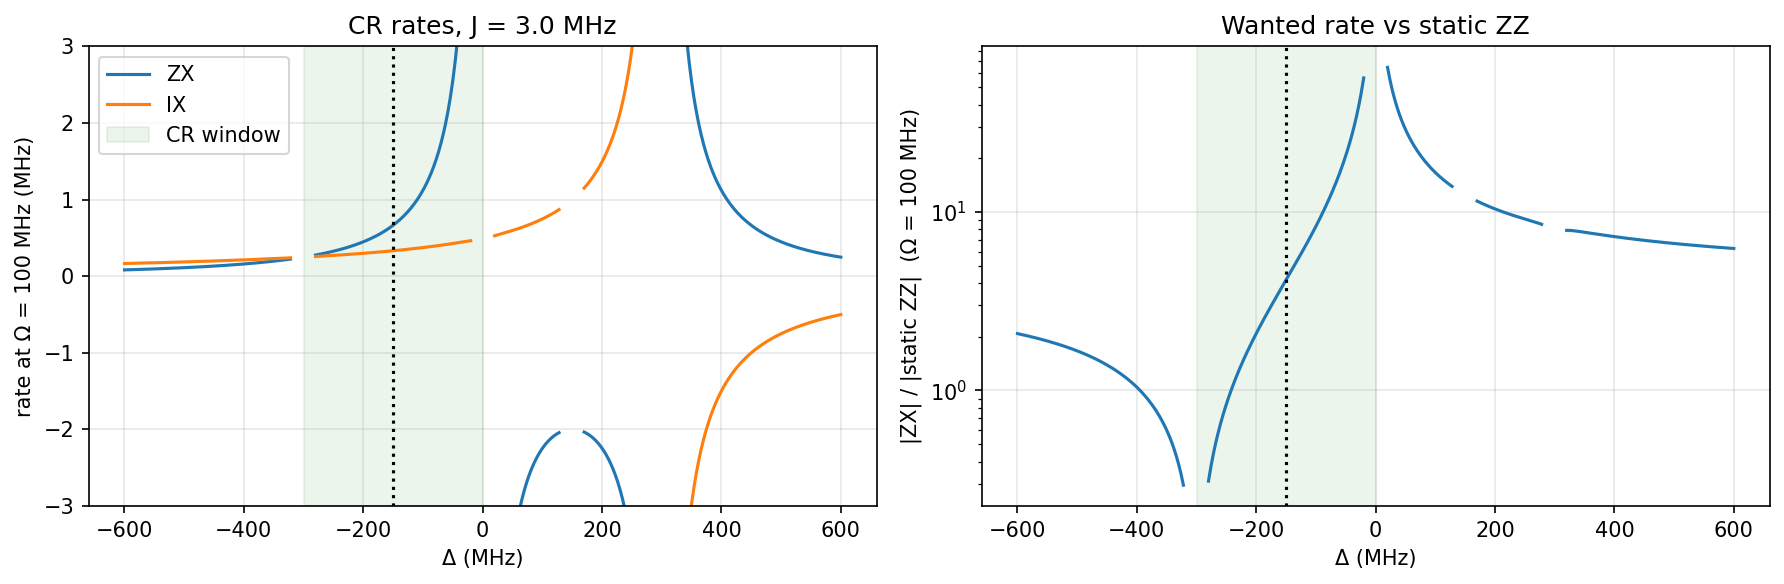

In [11]:
# ZX and IX per 100 MHz of drive vs detuning, collisions masked. Window with a_tgt < D < 0 is the usual CR regime.
Ds = np.linspace(-0.6, 0.6, 601)
col = np.array([0.0, alpha_tgt, -alpha_ctrl, -alpha_ctrl/2])
zx = np.full(Ds.size, np.nan); ix = np.full(Ds.size, np.nan); zt = np.full(Ds.size, np.nan)
for k, D in enumerate(Ds):
    if np.min(np.abs(D-col)) < 0.02: continue
    s_ = TwoQubit(f_tgt+D, alpha_ctrl, f_tgt, alpha_tgt, J, NLEV)
    rr = cr_rates(s_, 0.1); zx[k], ix[k], zt[k] = rr['ZX'], rr['IX'], rr['zeta_static']
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(Ds*1e3, zx, label='ZX'); ax[0].plot(Ds*1e3, ix, label='IX')
ax[0].axvspan(alpha_tgt*1e3, 0, color='g', alpha=0.08, label='CR window'); ax[0].axvline(sysd.Delta*1e3, color='k', ls=':')
ax[0].set_ylim(-3, 3); ax[0].set_xlabel('Δ (MHz)'); ax[0].set_ylabel('rate at Ω = 100 MHz (MHz)'); ax[0].set_title(f'CR rates, J = {J*1e3:.1f} MHz'); ax[0].legend()
ratio = np.abs(zx)/np.abs(zt)
ax[1].semilogy(Ds*1e3, ratio); ax[1].axvspan(alpha_tgt*1e3, 0, color='g', alpha=0.08); ax[1].axvline(sysd.Delta*1e3, color='k', ls=':')
ax[1].set_xlabel('Δ (MHz)'); ax[1].set_ylabel('|ZX| / |static ZZ|  (Ω = 100 MHz)'); ax[1].set_title('Wanted rate vs static ZZ'); 
plt.tight_layout(); plt.show()

Take-away: `ZX ∝ J·Ω` but static ZZ `∝ J²`. So **smaller J with a bigger drive** is the lower-ZZ route, until drive-induced leakage / Stark shifts / the gate-time budget stop you. Section 5 puts numbers on it.

## 4. CR pulse simulation

Pulse: flat-top with lifted-Gaussian edges on the control, carrier at the dressed target frequency.
Model: frame rotating at the qubit frequencies, RWA, time-dependent `J` phase `e^{iΔt}` and drive phase handled exactly (`QobjEvo` + `qt.sesolve`).

Plot = target Bloch vector (frame of the drive) for control in |0> and |1>. A good CR makes them rotate in **opposite** directions.

CR drive 60 MHz, flat-top 303 ns, total 323 ns
Note: the |2> population here is mostly *virtual* (drive-dressed states); it returns to ~0 when the pulse ends.
ZX angle: simulated 1.487 rad, first-order prediction 1.571 rad  (target pi/2 = 1.571)
The gap is the higher-order (drive-nonlinear) correction. The ECR calibration in section 6 absorbs it by tuning amplitude / length.


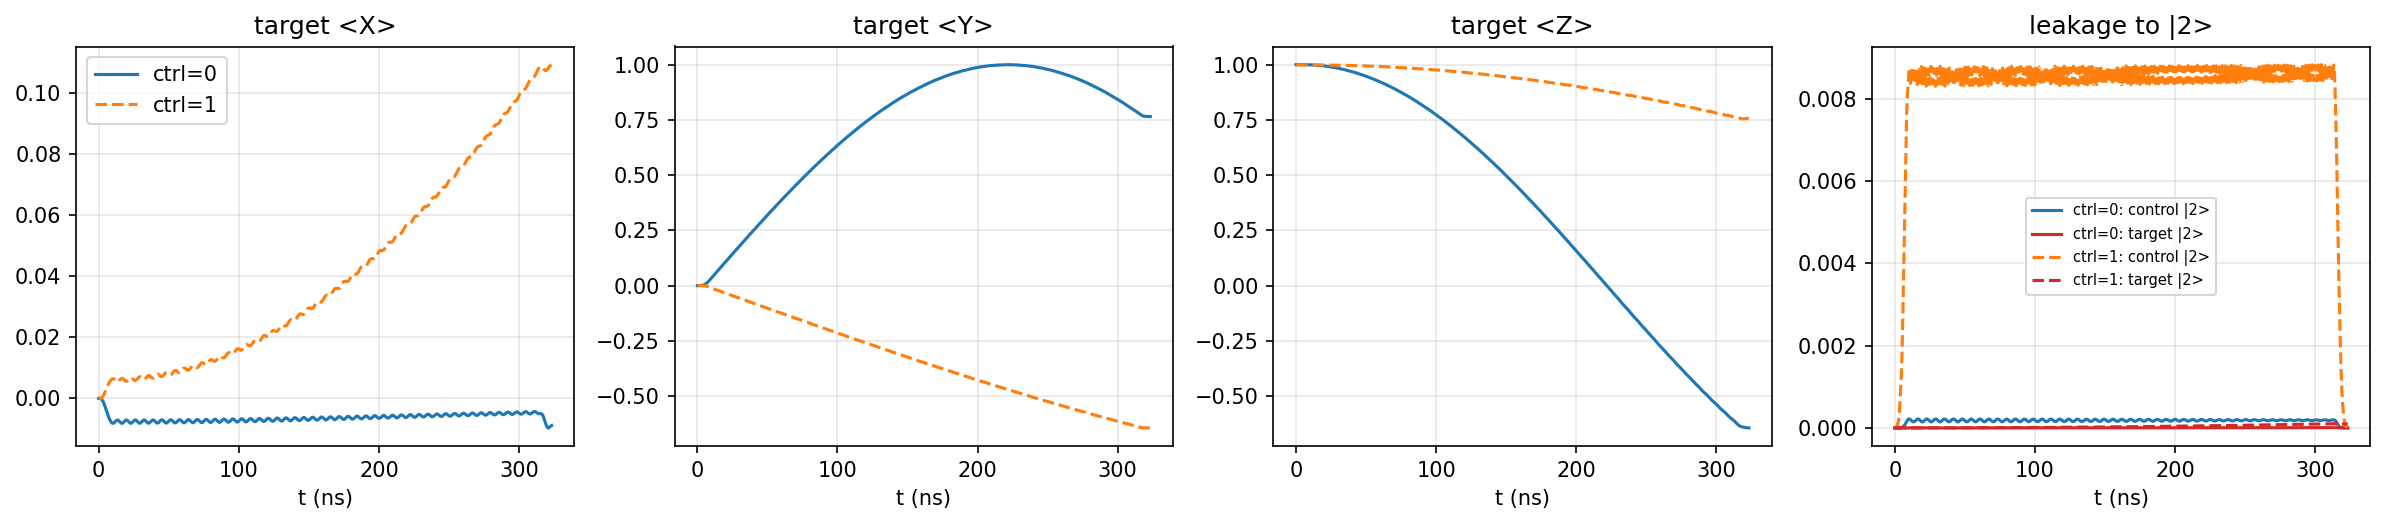

In [12]:
t_edge = 10.0
A_cr, tf_cr = guess_cr(sysd, 0.060, t_edge, theta=np.pi/2)       # first-order guess for a full pi/2 CR
print(f'CR drive {A_cr*1e3:.0f} MHz, flat-top {tf_cr:.0f} ns, total {tf_cr+2*t_edge:.0f} ns')
res = {c: cr_bloch(sysd, A_cr, tf_cr, t_edge, c) for c in (0, 1)}
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
for c, ls in ((0, '-'), (1, '--')):
    o = res[c]
    ax[0].plot(o['t'], o['X'], ls, label=f'ctrl={c}'); ax[1].plot(o['t'], o['Y'], ls); ax[2].plot(o['t'], o['Z'], ls)
    ax[3].plot(o['t'], o['P_c2'], ls, label=f'ctrl={c}: control |2>'); ax[3].plot(o['t'], o['P_t2'], ls, color='C3', label=f'ctrl={c}: target |2>' )
for a_, n in zip(ax, ['target <X>', 'target <Y>', 'target <Z>', 'leakage to |2>']): a_.set_title(n); a_.set_xlabel('t (ns)')
ax[0].legend(); ax[3].legend(fontsize=7); plt.tight_layout(); plt.show()
print('Note: the |2> population here is mostly *virtual* (drive-dressed states); it returns to ~0 when the pulse ends.')

# conditional rotation angle of the target (about X) and the ZX angle
ang = {c: np.unwrap(np.arctan2(res[c]['Y'], res[c]['Z'])) for c in (0, 1)}
zx_sim = (ang[0][-1]-ang[1][-1])/2
x0, x1 = r['IX']+r['ZX'], r['IX']-r['ZX']
r60 = cr_rates(sysd, abs(A_cr)); zx_pred = 2*TWO_PI*r60['ZX']*1e-3*(tf_cr+edge_area(t_edge))
print(f'ZX angle: simulated {zx_sim:.3f} rad, first-order prediction {zx_pred:.3f} rad  (target pi/2 = {np.pi/2:.3f})')
print('The gap is the higher-order (drive-nonlinear) correction. The ECR calibration in section 6 absorbs it by tuning amplitude / length.')

### Lab-frame cross-check of the **bare** CR (no rotating frame, no RWA)

Same pulse, now with full capacitive charge-charge coupling and a real `cos(ω_d t)` carrier on the control charge operator (`n = i(a†-a)`).

Note: for a bare CR the target rotates for **both** control states. The control's off-resonant response drives the target even when the control is |0>.
`ZX` only makes the two rotation rates *differ* (`IX ± ZX`). Fast agreement between the two models is what matters here, not the shape.

control |0>: final target P(1)  lab 0.8076  RWA 0.8216  max |diff| = 0.0146
control |1>: final target P(1)  lab 0.1337  RWA 0.1217  max |diff| = 0.0120
5 s


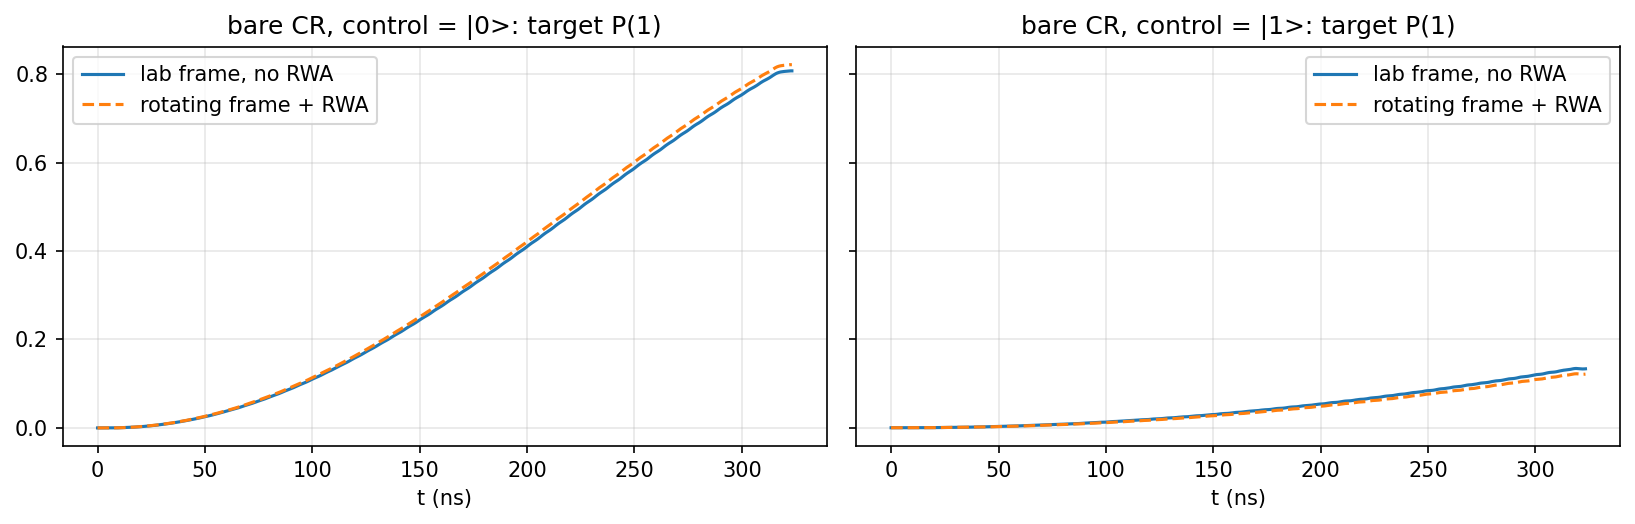

In [13]:
t0 = time.time()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for c in (0, 1):
    tl_, p_lab = lab_frame_cr(sysd, A_cr, tf_cr, t_edge, c, dt=0.01)
    ax[c].plot(tl_, p_lab, label='lab frame, no RWA'); ax[c].plot(res[c]['t'], res[c]['P_t1'], '--', label='rotating frame + RWA')
    ax[c].set_title(f'bare CR, control = |{c}>: target P(1)'); ax[c].set_xlabel('t (ns)'); ax[c].legend()
    print(f'control |{c}>: final target P(1)  lab {p_lab[-1]:.4f}  RWA {res[c]["P_t1"][-1]:.4f}  max |diff| = {np.max(np.abs(np.interp(res[c]["t"], tl_, p_lab)-res[c]["P_t1"])):.4f}')
plt.tight_layout(); plt.show(); print(f'{time.time()-t0:.0f} s')

### CR as a conditional flip: add a target cancellation tone

A weak tone on the **target** (same frequency, same envelope) cancels the target rotation for control = |0>. Then the target only moves when the control is |1>:
a CNOT-like conditional flip (a π/2 CR is a CNOT up to single-qubit gates). Amplitude is found by minimising target P(1) for control = |0>; the flat-top length by maximising P(1) for control = |1>.

CR drive 100 MHz, target cancellation tone -1.82 MHz, flat-top 205 ns (total 225 ns)
control |0>: final target P(1)  RWA 0.0002   lab frame 0.0006
control |1>: final target P(1)  RWA 0.9927   lab frame 0.9922


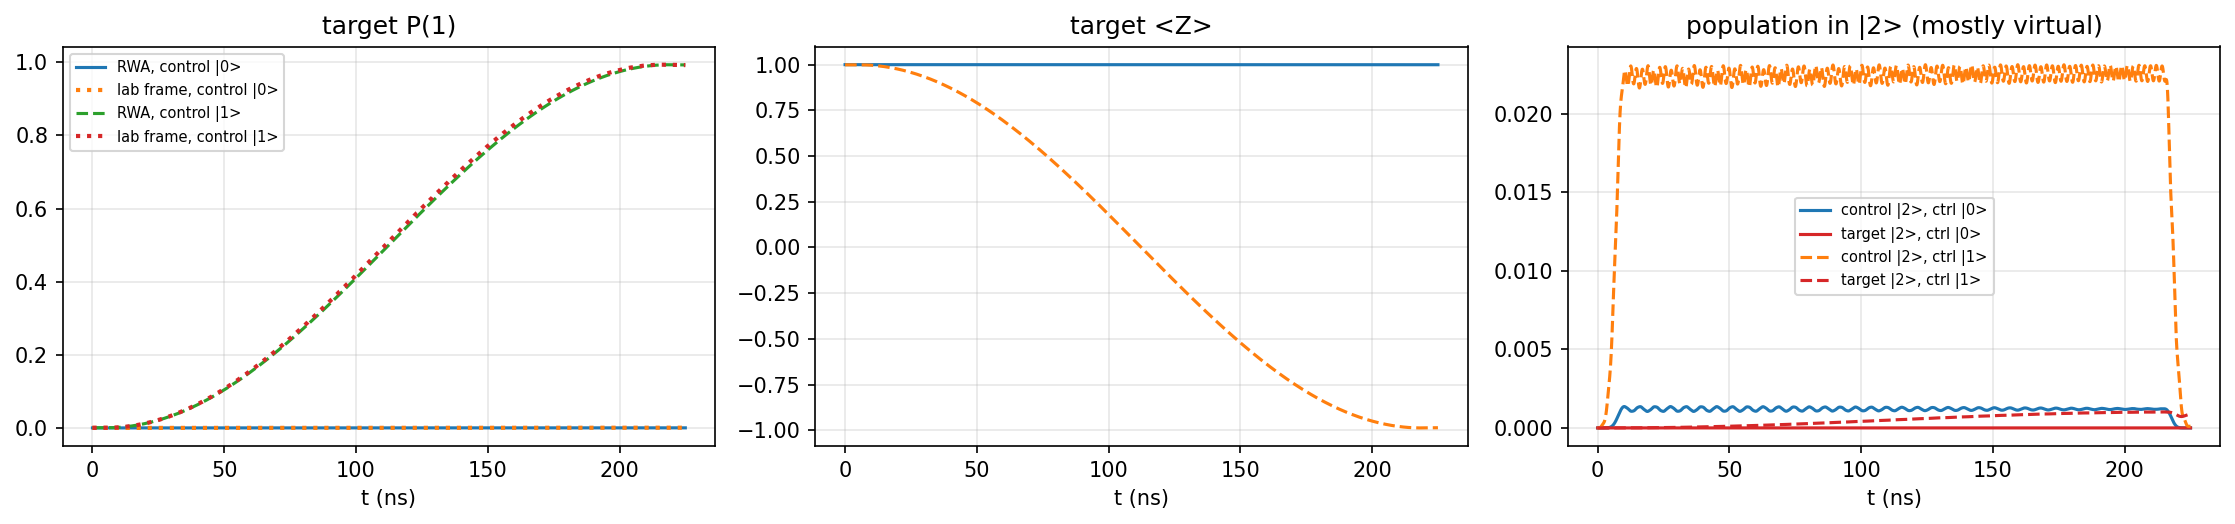

In [14]:
Om_flip = 0.10                                                   # control drive Rabi rate (GHz)
A_f, tf_f = guess_cr(sysd, Om_flip, t_edge, theta=np.pi/2)
A_t = calibrate_cancel_tone(sysd, A_f, tf_f, t_edge)
tf_f, ts_, p_ = tune_flip_length(sysd, A_f, A_t, tf_f, t_edge)
print(f'CR drive {A_f*1e3:.0f} MHz, target cancellation tone {A_t*1e3:+.2f} MHz, flat-top {tf_f:.0f} ns (total {tf_f+2*t_edge:.0f} ns)')
resf = {c: cr_bloch(sysd, A_f, tf_f, t_edge, c, A_t=A_t) for c in (0, 1)}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for c, ls in ((0, '-'), (1, '--')):
    tl_, p_lab = lab_frame_cr(sysd, A_f, tf_f, t_edge, c, dt=0.01, A_t=A_t)
    ax[0].plot(resf[c]['t'], resf[c]['P_t1'], ls, label=f'RWA, control |{c}>'); ax[0].plot(tl_, p_lab, ':', lw=2, label=f'lab frame, control |{c}>')
    ax[1].plot(resf[c]['t'], resf[c]['Z'], ls, label=f'control |{c}>')
    ax[2].plot(resf[c]['t'], resf[c]['P_c2'], ls, label=f'control |2>, ctrl |{c}>'); ax[2].plot(resf[c]['t'], resf[c]['P_t2'], ls, color='C3', label=f'target |2>, ctrl |{c}>')
    print(f'control |{c}>: final target P(1)  RWA {resf[c]["P_t1"][-1]:.4f}   lab frame {p_lab[-1]:.4f}')
ax[0].set_title('target P(1)'); ax[1].set_title('target <Z>'); ax[2].set_title('population in |2> (mostly virtual)')
for a_ in ax: a_.set_xlabel('t (ns)')
ax[0].legend(fontsize=7); ax[2].legend(fontsize=7); plt.tight_layout(); plt.show()

## 5. Design-space scan

Two stages, cheap first:

**(a) Perturbative maps (instant)** - gate time and static ZZ over `(Δ, J)` at a fixed drive.

**(b) Pulse-level ECR** on a small grid. For each design the CR amplitude and flat-top length are calibrated by Nelder-Mead on the average gate fidelity (virtual-Z allowed), including leakage.

Score = coherent error `(1-F)` + rough T1/T2-limited error of the sequence (`T1 = T2 = 100 µs` by default).

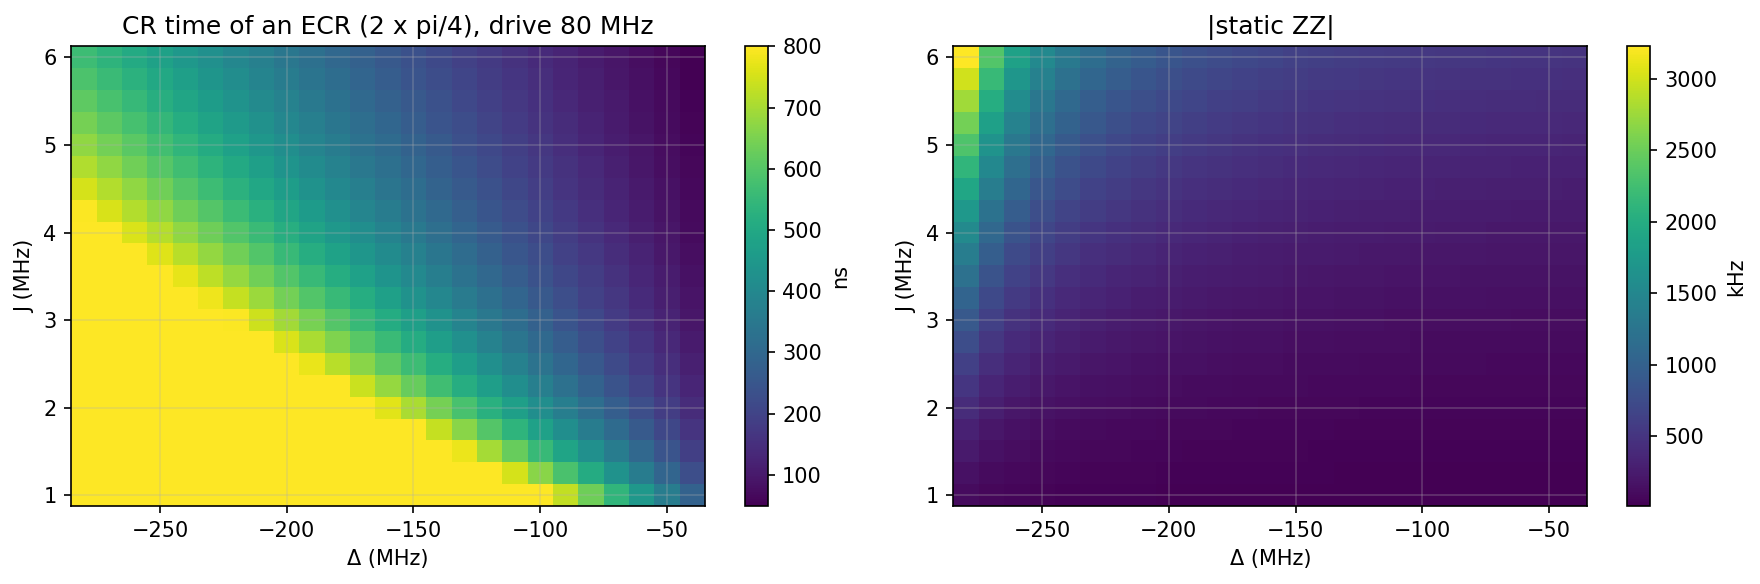

In [15]:
# (a) instant maps at fixed drive
Om_scan = 0.08
Dgrid = np.linspace(-0.28, -0.04, 25); Jgrid = np.linspace(1.0, 6.0, 21)*1e-3
Tmap = np.full((Jgrid.size, Dgrid.size), np.nan); Zmap = Tmap.copy()
for i, Jv in enumerate(Jgrid):
    for k, D in enumerate(Dgrid):
        s_ = TwoQubit(f_tgt+D, alpha_ctrl, f_tgt, alpha_tgt, Jv, NLEV)
        rr = cr_rates(s_, Om_scan)
        Tmap[i, k] = 2*(np.pi/4/(TWO_PI*abs(rr['ZX'])*1e-3))        # two CR halves, flat-top time only
        Zmap[i, k] = abs(rr['zeta_static'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].pcolormesh(Dgrid*1e3, Jgrid*1e3, Tmap, shading='auto', vmax=800); plt.colorbar(im, ax=ax[0], label='ns')
ax[0].set_title(f'CR time of an ECR (2 x pi/4), drive {Om_scan*1e3:.0f} MHz'); 
im = ax[1].pcolormesh(Dgrid*1e3, Jgrid*1e3, Zmap*1e3, shading='auto'); plt.colorbar(im, ax=ax[1], label='kHz')
ax[1].set_title('|static ZZ|')
for a_ in ax: a_.set_xlabel('Δ (MHz)'); a_.set_ylabel('J (MHz)')
plt.tight_layout(); plt.show()

In [16]:
# (b) pulse-level ECR scan (about 2-3 minutes). Set RUN_SCAN = False to skip and use the design knobs from section 1.
RUN_SCAN   = True
scan_D     = [-0.10, -0.15, -0.20]                  # GHz
scan_J     = [0.002, 0.003, 0.004]                  # GHz
T1_us = T2_us = 100.0                               # for the coherence-limited part of the score
def dec_error(T_ns):                                # avg-gate-infidelity estimate for 2 idle-ish qubits
    return 2*(T_ns/(3*T2_us*1e3) + T_ns/(6*T1_us*1e3))

table = []
if RUN_SCAN:
    t0 = time.time()
    for D in scan_D:
        for Jv in scan_J:
            s_ = TwoQubit(f_tgt+D, alpha_ctrl, f_tgt, alpha_tgt, Jv, NLEV)
            c_ = calibrate_ecr(s_, 0.08, maxiter=60, fit_phase=False)
            table.append(dict(D=D, J=Jv, F=c_['F'], leak=c_['leak'], T=c_['T'], A=c_['A'], tf=c_['t_flat'], zeta=dressed_info(s_)['zz_MHz'],
                              score=(1-c_['F'])+dec_error(c_['T'])))
            print(f"D={D*1e3:+4.0f} MHz  J={Jv*1e3:.0f} MHz | F={c_['F']:.5f}  leak={c_['leak']:.1e}  T={c_['T']:.0f} ns  Omega_cr={c_['A']*1e3:.0f} MHz  ZZ={table[-1]['zeta']:+.3f} MHz | score={table[-1]['score']:.5f}", flush=True)
    print(f'{time.time()-t0:.0f} s')

D=-100 MHz  J=2 MHz | F=0.99457  leak=4.6e-05  T=275 ns  Omega_cr=82 MHz  ZZ=+0.060 MHz | score=0.00817
D=-100 MHz  J=3 MHz | F=0.99690  leak=4.7e-05  T=214 ns  Omega_cr=74 MHz  ZZ=+0.135 MHz | score=0.00525
D=-100 MHz  J=4 MHz | F=0.99685  leak=5.7e-05  T=154 ns  Omega_cr=94 MHz  ZZ=+0.240 MHz | score=0.00469
D=-150 MHz  J=2 MHz | F=0.99860  leak=7.5e-06  T=423 ns  Omega_cr=80 MHz  ZZ=+0.071 MHz | score=0.00563
D=-150 MHz  J=3 MHz | F=0.99696  leak=1.6e-05  T=289 ns  Omega_cr=82 MHz  ZZ=+0.160 MHz | score=0.00593
D=-150 MHz  J=4 MHz | F=0.99689  leak=2.5e-05  T=210 ns  Omega_cr=96 MHz  ZZ=+0.284 MHz | score=0.00521
D=-200 MHz  J=2 MHz | F=0.99635  leak=1.2e-04  T=538 ns  Omega_cr=90 MHz  ZZ=+0.096 MHz | score=0.00903
D=-200 MHz  J=3 MHz | F=0.99336  leak=1.8e-04  T=367 ns  Omega_cr=91 MHz  ZZ=+0.216 MHz | score=0.01032
D=-200 MHz  J=4 MHz | F=0.98640  leak=3.0e-04  T=296 ns  Omega_cr=85 MHz  ZZ=+0.383 MHz | score=0.01656
251 s


Best by score: Δ = -100 MHz, J = 4 MHz -> F = 0.99685, T = 154 ns


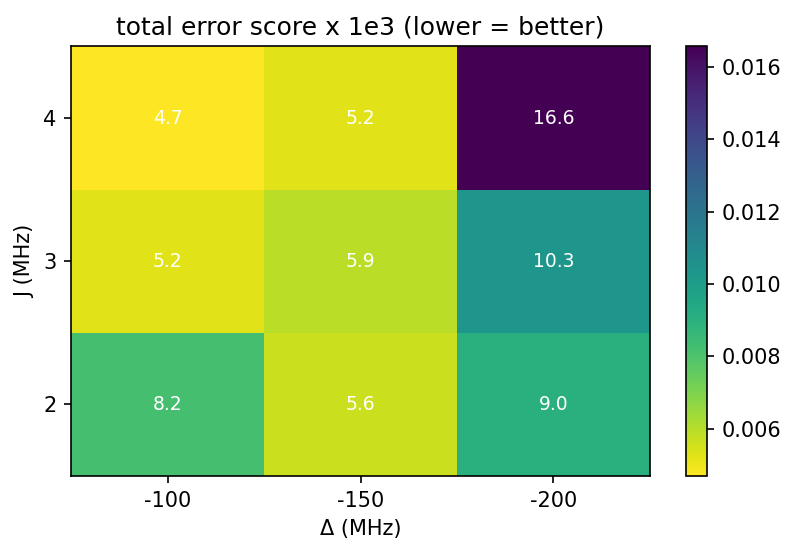

In [17]:
if RUN_SCAN:
    best = min(table, key=lambda d: d['score'])
    print(f"Best by score: Δ = {best['D']*1e3:+.0f} MHz, J = {best['J']*1e3:.0f} MHz -> F = {best['F']:.5f}, T = {best['T']:.0f} ns")
    Fm = np.array([[ [t for t in table if t['D']==D and t['J']==Jv][0]['score'] for D in scan_D] for Jv in scan_J])
    fig, ax = plt.subplots(figsize=(5.5, 3.8)); im = ax.imshow(Fm, origin='lower', aspect='auto', cmap='viridis_r')
    ax.set_xticks(range(len(scan_D))); ax.set_xticklabels([f'{d*1e3:.0f}' for d in scan_D]); ax.set_yticks(range(len(scan_J))); ax.set_yticklabels([f'{j*1e3:.0f}' for j in scan_J])
    for i in range(len(scan_J)):
        for k in range(len(scan_D)): ax.text(k, i, f'{Fm[i,k]*1e3:.1f}', ha='center', va='center', color='w', fontsize=9)
    ax.set_xlabel('Δ (MHz)'); ax.set_ylabel('J (MHz)'); ax.set_title('total error score x 1e3 (lower = better)'); ax.grid(False); plt.colorbar(im); plt.tight_layout(); plt.show()
    f_ctrl_opt, f_tgt_opt, J_opt = f_tgt+best['D'], f_tgt, best['J']
else:
    f_ctrl_opt, f_tgt_opt, J_opt = f_ctrl, f_tgt, J

Rules of thumb that fall out of the scan:

- Larger `|Δ|` ⇒ slower gate; smaller `|Δ|` ⇒ faster but more drive-induced leakage / Stark shift and closer to the Δ = 0 collision.
- Static ZZ (`∝ J²`) shows up as a coherent error that the echo only partly cancels, so lowering `J` and raising the drive helps until time (T1) bites.
- Anharmonicity: larger `|α|` widens the CR window and improves collision margins, at the cost of larger `EC` (smaller `C_Σ`).

## 6. ECR gate

Sequence: `CR(+) → X(π) on control → CR(-)`, each CR is a ZX rotation of π/4 so the total is ZX(π/2) (maximally entangling).
The echo cancels IX/IY and the static ZZ/ZI to first order. Ideal operator: `ZX(-π/4)·X_c·ZX(+π/4)`.

The X(π) pulse is a 20 ns lifted Gaussian at the dressed control frequency. DRAG, rotary tones on the target and direct-drive crosstalk are not included (easy extensions).

In [18]:
# calibrate ECR at the chosen design (scan winner, or the design knobs if RUN_SCAN = False)
sys_e = TwoQubit(f_ctrl_opt, alpha_ctrl, f_tgt_opt, alpha_tgt, J_opt, NLEV)
t0 = time.time()
cal = calibrate_ecr(sys_e, 0.08, maxiter=120, fit_phase=False)
print(f"design: f_ctrl = {f_ctrl_opt:.3f}, f_tgt = {f_tgt_opt:.3f} GHz, J = {J_opt*1e3:.1f} MHz, static ZZ = {dressed_info(sys_e)['zz_MHz']:+.3f} MHz")
print(f"calibrated: CR amplitude = {cal['A']*1e3:.1f} MHz (Rabi rate), flat-top = {cal['t_flat']:.1f} ns per CR, edges 10 ns, total gate = {cal['T']:.0f} ns")
print(f"average gate fidelity (coherent, virtual-Z allowed) = {cal['F']:.5f},  leakage = {cal['leak']:.2e}   [{time.time()-t0:.0f} s]")

design: f_ctrl = 4.900, f_tgt = 5.000 GHz, J = 4.0 MHz, static ZZ = +0.240 MHz
calibrated: CR amplitude = 93.8 MHz (Rabi rate), flat-top = 45.2 ns per CR, edges 10 ns, total gate = 154 ns
average gate fidelity (coherent, virtual-Z allowed) = 0.99685,  leakage = 5.69e-05   [16 s]


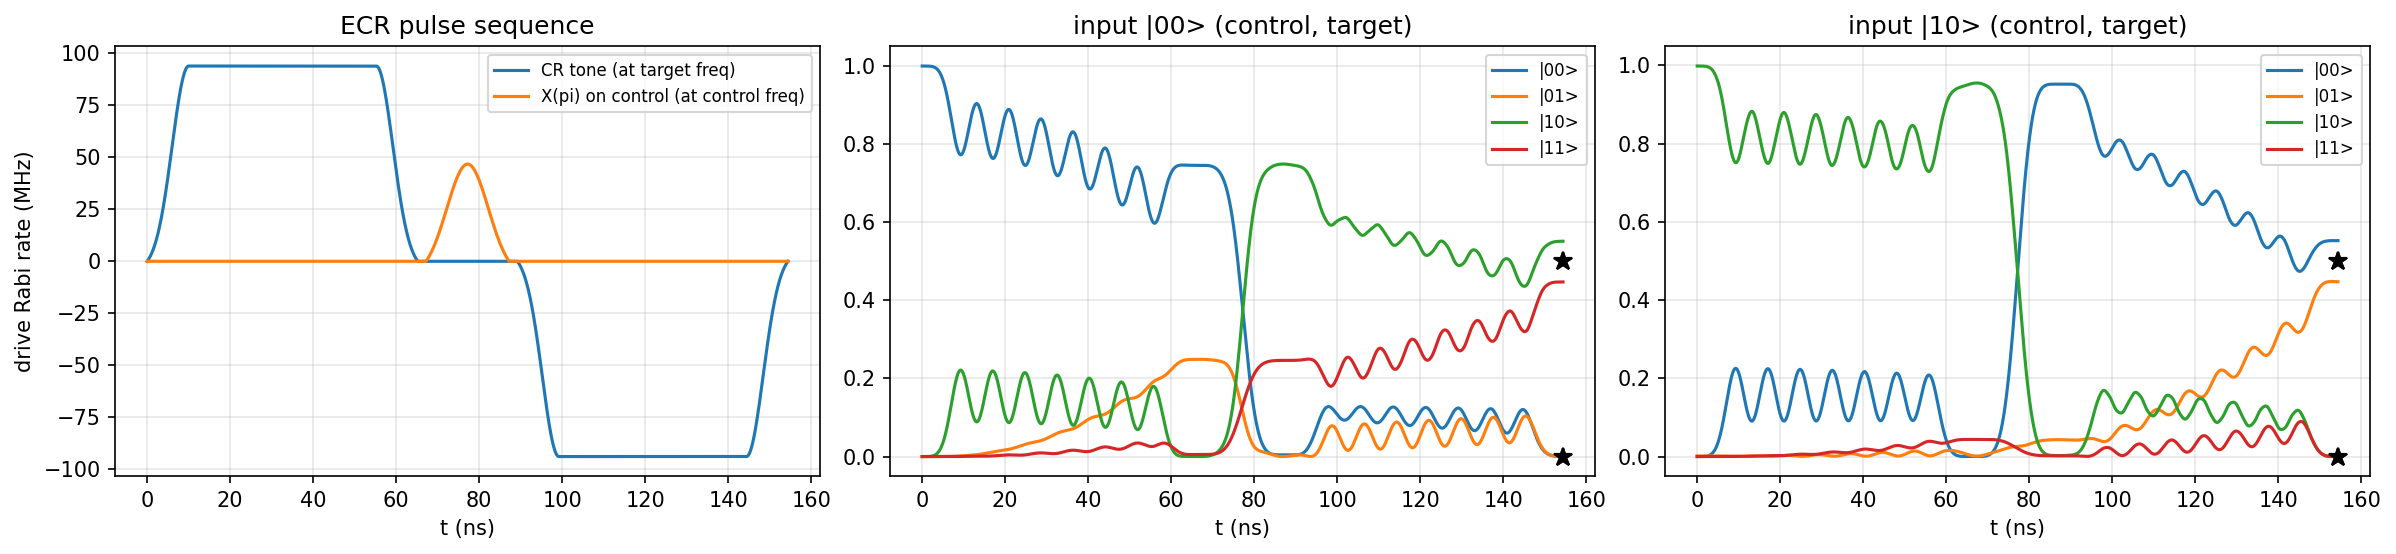

In [19]:
# pulse sequence and population dynamics for computational inputs.
# NOTE: ECR is maximally entangling, so the ideal final populations are 50/50, NOT 0/1 (stars = ideal ECR). See the CNOT-equivalent check below.
tl_e, dr_e, T_e = ecr_sequence(sys_e, cal['A'], cal['t_flat'], 10.0)
H_e = build_H_evo(sys_e, tl_e, dr_e)
d = sys_e.nlev; labs = label_eigs(sys_e.H_lab(), d)
kets = {k: qt.Qobj(labs[k][1].reshape(-1, 1), dims=[[d, d], [1, 1]]) for k in sys_e.comp}
P = lambda i, j: qt.tensor(qt.fock_dm(d, i), qt.fock_dm(d, j))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].plot(tl_e, dr_e[0][2].real*1e3, label='CR tone (at target freq)'); ax[0].plot(tl_e, dr_e[1][2].real*1e3, label='X(pi) on control (at control freq)')
ax[0].set_xlabel('t (ns)'); ax[0].set_ylabel('drive Rabi rate (MHz)'); ax[0].set_title('ECR pulse sequence'); ax[0].legend(fontsize=8)
for k, c_ in zip([(0, 0), (1, 0)], ['C0', 'C1']):
    out = qt.sesolve(H_e, kets[k], tl_e, e_ops=[P(i, j) for i in range(2) for j in range(2)], options={'atol': 1e-10, 'rtol': 1e-8, 'nsteps': 10**6, 'method': 'vern9'})
    Uid = ecr_ideal(); kcol = sys_e.comp.index(k)
    for n_, (i, j) in enumerate([(a_, b_) for a_ in range(2) for b_ in range(2)]):
        (ax[1] if k == (0, 0) else ax[2]).plot(tl_e, np.real(out.expect[n_]), label=f'|{i}{j}>')
        (ax[1] if k == (0, 0) else ax[2]).plot([tl_e[-1]], [abs(Uid[n_, kcol])**2], '*', color='k', ms=9)
    (ax[1] if k == (0, 0) else ax[2]).set_title(f'input |{k[0]}{k[1]}> (control, target)'); (ax[1] if k == (0, 0) else ax[2]).set_xlabel('t (ns)'); (ax[1] if k == (0, 0) else ax[2]).legend(fontsize=8)
plt.tight_layout(); plt.show()

F_avg = 0.99685, leakage = 5.69e-05, 1-F = 3.15e-03
Dominant coherent error generators (rad, residual unitary ~ exp(-i G)):
   ZX: -0.0526
   XI: +0.0171
   IY: -0.0155
   ZZ: +0.0154
   YX: -0.0131
   YY: -0.0084
   XX: -0.0061
   YZ: +0.0061


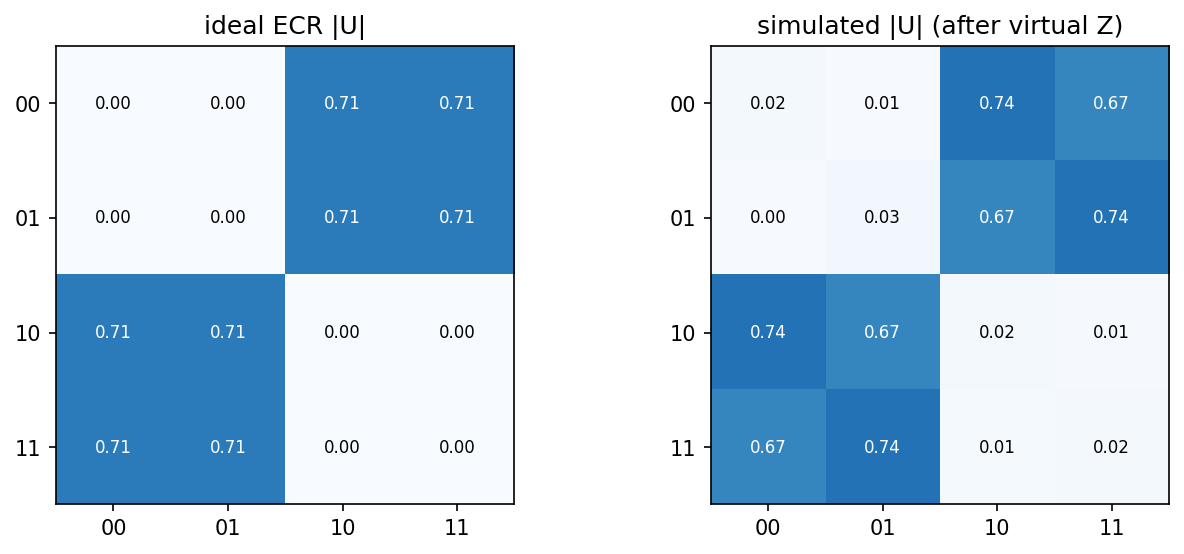

In [20]:
# gate matrix vs ideal, and error budget
Ub = comp_block(sys_e, propagate_U(sys_e, tl_e, dr_e), T_e)
Fv, zopt = fidelity_with_virtual_z(Ub, ecr_ideal(), n_starts=6)
Zl = lambda p: np.kron(Rz(p[0]), Rz(p[1]))
Usim = Zl(zopt[:2]) @ Ub @ Zl(zopt[2:])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a_, M, t_ in [(ax[0], ecr_ideal(), 'ideal ECR |U|'), (ax[1], Usim, 'simulated |U| (after virtual Z)')]:
    im = a_.imshow(np.abs(M), vmin=0, vmax=1, cmap='Blues'); a_.set_title(t_); a_.grid(False)
    a_.set_xticks(range(4)); a_.set_yticks(range(4)); a_.set_xticklabels(['00','01','10','11']); a_.set_yticklabels(['00','01','10','11'])
    for i in range(4):
        for j in range(4): a_.text(j, i, f'{abs(M[i,j]):.2f}', ha='center', va='center', color='k' if abs(M[i,j]) < 0.6 else 'w', fontsize=8)
plt.tight_layout(); plt.show()

M = ecr_ideal().conj().T @ Usim
u, sv, vh = np.linalg.svd(M); G = 1j*logm(u@vh); cc = pauli_decomp(G)
print(f'F_avg = {Fv:.5f}, leakage = {leakage(Ub):.2e}, 1-F = {1-Fv:.2e}')
print('Dominant coherent error generators (rad, residual unitary ~ exp(-i G)):')
for k, v in sorted(cc.items(), key=lambda kv: -abs(kv[1])):
    if k != 'II' and abs(v) > 5e-3: print(f'   {k}: {v:+.4f}')

### Why the ECR populations do not go to 0 / 1

`ECR ∝ ZX(π/2) · X_c` is a **maximally entangling** gate, not a permutation. Ideal: |00> → equal superposition of |10> and |11> (50 / 50). The simulation reproduces that.
To see clean 0 / 1 outcomes, wrap the ECR in single-qubit gates so it becomes a **CNOT** (standard compilation). The cell below fits those local gates on the *ideal* ECR only, then applies the same gates to the *simulated* ECR.

ECR truth table (final populations), ideal vs simulated, no extra gates:
  in |00>  ideal [0.  0.  0.5 0.5]   sim [0.    0.    0.552 0.448]
  in |01>  ideal [0.  0.  0.5 0.5]   sim [0.    0.001 0.447 0.552]
  in |10>  ideal [0.5 0.5 0.  0. ]   sim [0.552 0.447 0.001 0.   ]
  in |11>  ideal [0.5 0.5 0.  0. ]   sim [0.448 0.552 0.    0.   ]

local-gate fit of ideal ECR -> CNOT: residual 0.0e+00
CNOT-equivalent truth table (rows = input |ctrl tgt>, columns = output |00>,|01>,|10>,|11>):
  in |00>  CNOT [1. 0. 0. 0.]   sim [0.996 0.003 0.    0.001]
  in |01>  CNOT [0. 1. 0. 0.]   sim [0.003 0.996 0.    0.   ]
  in |10>  CNOT [0. 0. 0. 1.]   sim [0.001 0.    0.003 0.996]
  in |11>  CNOT [0. 0. 1. 0.]   sim [0.    0.    0.997 0.003]
average gate fidelity vs CNOT: 0.99685  (leakage not included in this block)


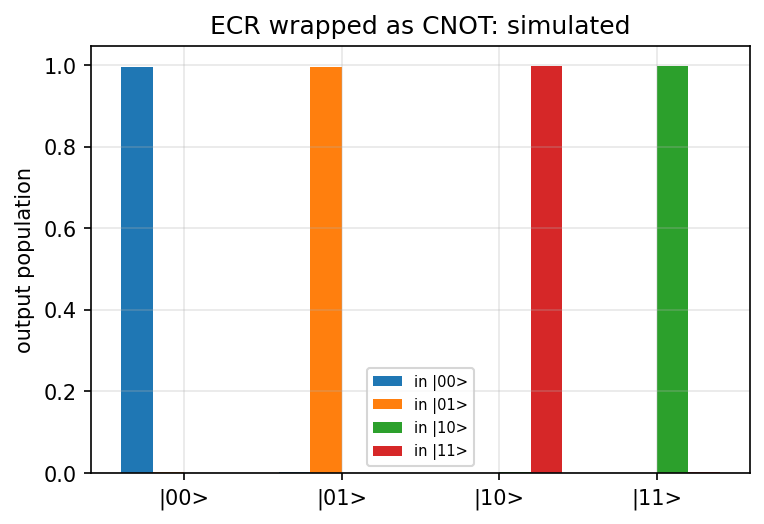

In [21]:
labels = ['00', '01', '10', '11']
Uid = ecr_ideal()
print('ECR truth table (final populations), ideal vs simulated, no extra gates:')
for k in range(4):
    print(f'  in |{labels[k]}>  ideal {np.round(np.abs(Uid[:, k])**2, 3)}   sim {np.round(np.abs(Usim[:, k])**2, 3)}')

pfit, resid = fit_local_cnot(Uid)
Lpost, Lpre = local_gates(pfit)
Mc = Lpost @ Usim @ Lpre                          # simulated ECR wrapped in the fitted single-qubit gates
print(f'\nlocal-gate fit of ideal ECR -> CNOT: residual {resid:.1e}')
print('CNOT-equivalent truth table (rows = input |ctrl tgt>, columns = output |00>,|01>,|10>,|11>):')
for k in range(4):
    print(f'  in |{labels[k]}>  CNOT {np.round(np.abs(CNOT[:, k])**2, 0)}   sim {np.round(np.abs(Mc[:, k])**2, 3)}')
print(f'average gate fidelity vs CNOT: {avg_fidelity(CNOT.conj().T @ Mc):.5f}  (leakage not included in this block)')
fig, ax = plt.subplots(figsize=(5.2, 3.6)); w = 0.2
for k in range(4): ax.bar(np.arange(4)+(k-1.5)*w, np.abs(Mc[:, k])**2, w, label=f'in |{labels[k]}>')
ax.set_xticks(range(4)); ax.set_xticklabels(['|00>', '|01>', '|10>', '|11>']); ax.set_ylabel('output population'); ax.set_title('ECR wrapped as CNOT: simulated'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [22]:
# decoherence: master equation (mesolve) on |00>, T1 / T2 as set in section 5; compare with the coherent-only state
c_ops = collapse_ops(sys_e, T1_us, T2_us)
rho0 = kets[(0, 0)]*kets[(0, 0)].dag()
t0 = time.time()
r_dec = qt.mesolve(H_e, rho0, tl_e, c_ops, options={'atol': 1e-9, 'rtol': 1e-7, 'nsteps': 10**6, 'method': 'vern9'})
r_coh = qt.sesolve(H_e, kets[(0, 0)], tl_e, options={'atol': 1e-10, 'rtol': 1e-8, 'nsteps': 10**6, 'method': 'vern9'})
psi_f = r_coh.states[-1]; rho_f = r_dec.states[-1]
print(f'state fidelity of ECR|00> with decoherence (T1 = {T1_us:.0f} us, T2 = {T2_us:.0f} us) vs coherent evolution: {qt.expect(psi_f.proj(), rho_f):.5f}   [{time.time()-t0:.0f} s]')
print(f'rough T1/T2 error of the sequence from the formula in section 5: {dec_error(T_e):.5f}')

state fidelity of ECR|00> with decoherence (T1 = 100 us, T2 = 100 us) vs coherent evolution: 0.99879   [0 s]
rough T1/T2 error of the sequence from the formula in section 5: 0.00154


## 7. Targets for the layout

These are the numbers to mimic in the layout / EM (ADS, ElmerFEM) and verify after extraction.
`C_Σ` from `EC = e²/2C_Σ`. `C_g` is a weak-coupling estimate from `J ≈ ½ · C_g/√(C_1 C_2) · √(f_1 f_2)`; check it in EM.

In [23]:
import csv
EJ1, EC1 = solve_EJ_EC(f_ctrl_opt, alpha_ctrl); EJ2, EC2 = solve_EJ_EC(f_tgt_opt, alpha_tgt)
C1, C2 = e_over_h/EC1, e_over_h/EC2                                         # fF
Cg = 2*J_opt*np.sqrt(C1*C2)/np.sqrt(f_ctrl_opt*f_tgt_opt)                    # fF
Ic = lambda EJ: 4*np.pi*const.e*EJ*1e9*1e9
spec = [
 ('f_control_GHz', f_ctrl_opt), ('anharm_control_GHz', alpha_ctrl), ('EJ_control_GHz', EJ1), ('EC_control_GHz', EC1), ('C_sum_control_fF', C1), ('Ic_control_nA', Ic(EJ1)),
 ('f_target_GHz', f_tgt_opt),   ('anharm_target_GHz', alpha_tgt),   ('EJ_target_GHz', EJ2),  ('EC_target_GHz', EC2),  ('C_sum_target_fF', C2),  ('Ic_target_nA', Ic(EJ2)),
 ('detuning_ctrl_minus_tgt_MHz', (f_ctrl_opt-f_tgt_opt)*1e3), ('J_exchange_MHz', J_opt*1e3), ('Cg_estimate_fF', Cg),
 ('static_ZZ_MHz', dressed_info(sys_e)['zz_MHz']), ('ECR_CR_amplitude_MHz', cal['A']*1e3), ('ECR_flat_top_ns_per_CR', cal['t_flat']),
 ('ECR_total_ns', cal['T']), ('ECR_avg_gate_fidelity_coherent', cal['F']), ('ECR_leakage', cal['leak'])]
for k, v in spec: print(f'{k:34s} {v:12.5f}')
with open('ecr_design_targets.csv', 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['parameter', 'value']); w.writerows(spec)
print('\nsaved ecr_design_targets.csv')

f_control_GHz                           4.90000
anharm_control_GHz                     -0.30000
EJ_control_GHz                         12.84589
EC_control_GHz                          0.26069
C_sum_control_fF                       74.30302
Ic_control_nA                          25.86332
f_target_GHz                            5.00000
anharm_target_GHz                      -0.30000
EJ_target_GHz                          13.30992
EC_target_GHz                           0.26147
C_sum_target_fF                        74.08121
Ic_target_nA                           26.79759
detuning_ctrl_minus_tgt_MHz          -100.00000
J_exchange_MHz                          4.00000
Cg_estimate_fF                          0.11991
static_ZZ_MHz                           0.23976
ECR_CR_amplitude_MHz                   93.80834
ECR_flat_top_ns_per_CR                 45.20076
ECR_total_ns                          154.40152
ECR_avg_gate_fidelity_coherent          0.99685
ECR_leakage                             

### Notes and limits

- Transmons are Duffing oscillators (3 levels). Section 2 shows the exact-cosine static ZZ differs by a few %; use the exact value for final numbers.
- RWA frame model is checked against the lab-frame sim (section 4); agreement is at the ~1% level in populations.
- Not included: DRAG, target rotary tone, direct-drive crosstalk, readout resonators, TLS / flux noise, thermal population. Add as extra `drives` entries in `ecr_sequence`.
- A small residual ZX in the printed error generators does not mean mis-calibration: (amplitude, length) are already at the fidelity optimum, so it is a trade-off against the other terms.
- The first-order ZX formula is only the starting guess. The calibrated amplitude / length from the ECR section are the numbers to trust.